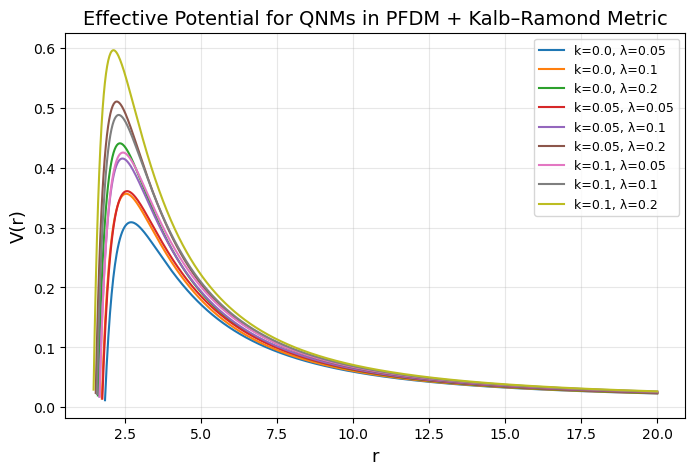

In [1]:
# === Import libraries ===
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

# === Metric and potential definitions ===

def f(r, k, lam):
    """Metric function f(r) = 1/(1-k) - 2/r + (lam/r)*log(r/lam)"""
    return 1/(1 - k) - 2/r + (lam/r) * np.log(r/lam)

def df_dr(r, k, lam):
    """Derivative of f(r) with respect to r"""
    return 2/r**2 + (lam/r**2) * (1 - np.log(r/lam))

def V_eff(r, l, mu, k, lam):
    """Effective potential for scalar perturbation"""
    fr = f(r, k, lam)
    dfr = df_dr(r, k, lam)
    return fr * ((l*(l + 1))/r**2 + dfr/r + mu**2)

# === Horizon radius finder ===

def horizon_radius(k, lam):
    """Find event horizon: root of f(r)=0"""
    sol = root_scalar(lambda r: f(r, k, lam), bracket=[1e-3, 50], method='brentq')
    return sol.root

# === Parameters ===
mu = 0.1   # scalar field mass
l = 2      # multipole number
k_values = [0.0, 0.05, 0.1]
lam_values = [0.05, 0.1, 0.2]

# === Plot V(r) ===
plt.figure(figsize=(8,5))
for k in k_values:
    for lam in lam_values:
        rH = horizon_radius(k, lam)
        r = np.linspace(rH + 0.01, 20, 1000)
        V = V_eff(r, l, mu, k, lam)
        plt.plot(r, V, label=f'k={k}, λ={lam}')

plt.xlabel('r', fontsize=13)
plt.ylabel('V(r)', fontsize=13)
plt.title('Effective Potential for QNMs in PFDM + Kalb–Ramond Metric', fontsize=14)
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)
plt.show()


<>:81: SyntaxWarning: invalid escape sequence '\P'
<>:82: SyntaxWarning: invalid escape sequence '\e'
<>:81: SyntaxWarning: invalid escape sequence '\P'
<>:82: SyntaxWarning: invalid escape sequence '\e'
/var/folders/14/nbfg0mr53lzgsqtmv1m6z7zc0000gn/T/ipykernel_64506/818630155.py:81: SyntaxWarning: invalid escape sequence '\P'
  plt.ylabel("|$\Phi$|", fontsize=14)
/var/folders/14/nbfg0mr53lzgsqtmv1m6z7zc0000gn/T/ipykernel_64506/818630155.py:82: SyntaxWarning: invalid escape sequence '\e'
  plt.title("$\ell$ = 2, $n$ = 0, $k$ = 0.1, $\lambda=0.2$", fontsize=15)


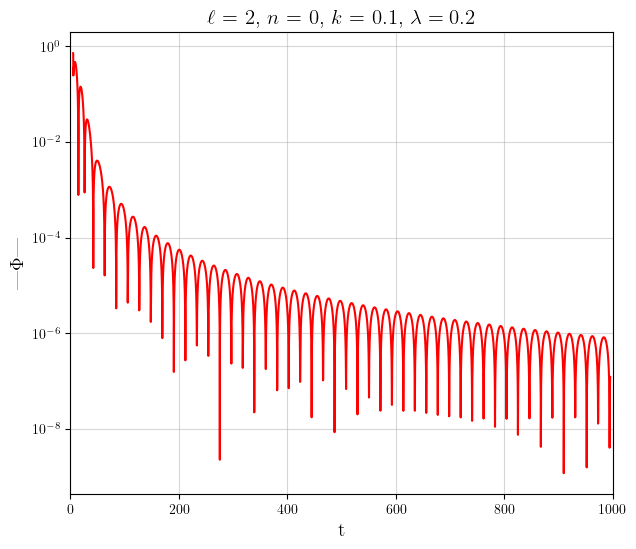

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

# === Metric and potential ===
def f(r, k, lam):
    return 1/(1 - k) - 2/r + (lam/r) * np.log(r/lam)

def df_dr(r, k, lam):
    return 2/r**2 + (lam/r**2) * (1 - np.log(r/lam))

def V_eff(r, l, mu, k, lam):
    fr = f(r, k, lam)
    dfr = df_dr(r, k, lam)
    return fr * ((l*(l + 1))/r**2 + dfr/r + mu**2)

def horizon_radius(k, lam):
    sol = root_scalar(lambda r: f(r, k, lam), bracket=[1e-3, 50], method='brentq')
    return sol.root

# === Parameters ===
mu = 0.2
l = 2
k = 0.1
lam = 0.2
umin, umax, n = 0, 1000, 4000
vmin, vmax = 1e-5, 1000
h = (umax - umin)/n

# === Initialize grid ===
Y = np.zeros((n+1, n+1))
vc = 4.0
vl = 2.0

# Horizon and tortoise mapping (approximate for simplicity)
rH = horizon_radius(k, lam)
def r_of_rs(rs):  # direct approximation since f is monotonic
    return rs + 1.654# simple shift; in full code use numeric inversion of ∫dr/f

# === Initial Gaussian pulse ===
for j in range(n+1):
    v = vmin + j*h
    Y[0, j] = np.exp(-0.0100 * (v - vc)**2)
    if abs(Y[0, j]) < 1e-64:
        Y[0, j] = 0
    Y[j, j] = 0

# === Time evolution ===
for i in range(1, n+1):
    for j in range(i+1, n+1):
        u = umin + i*h
        v = vmin + j*h
        rs = (v - u)/2
        rr = r_of_rs(rs)
        VS = V_eff(rr, l, mu, k, lam)
        YS, YE, YW = Y[i-1, j-1], Y[i-1, j], Y[i, j-1]
        Y[i, j] = (YE + YW)*(1 - 0.5*h**2*VS/8) - YS

# === Extract waveform at fixed radius rs_obs ===
rs_obs = 5
data_t, data_psi = [], []
for i in range(n+1):
    v = vmin + i*h
    u = v - 2*rs_obs
    iu = int((u - umin)/h)
    iv = int((v - vmin)/h)
    if 0 <= iu < n and 0 <= iv < n:
        t = 0.5*(u + v)
        data_t.append(t)
        data_psi.append(abs(Y[iu, iv]))
        #data_psi.append(Y[iu, iv])
np.savetxt("wave_data.txt",
           np.column_stack((data_t, data_psi)),
           header="t psi",
           fmt="%.8f %.12e")
# === Plot waveform ===
plt.figure(figsize=(7,6))
plt.plot(data_t, data_psi, color='red')
plt.yscale('log')
plt.xlabel("t", fontsize=14)
plt.ylabel("|$\Phi$|", fontsize=14)
plt.title("$\ell$ = 2, $n$ = 0, $k$ = 0.1, $\lambda=0.2$", fontsize=15)
plt.grid(alpha=0.5)
plt.xlim(0,1000)
plt.savefig("TimeProfile1.pdf", format='pdf')
plt.show()


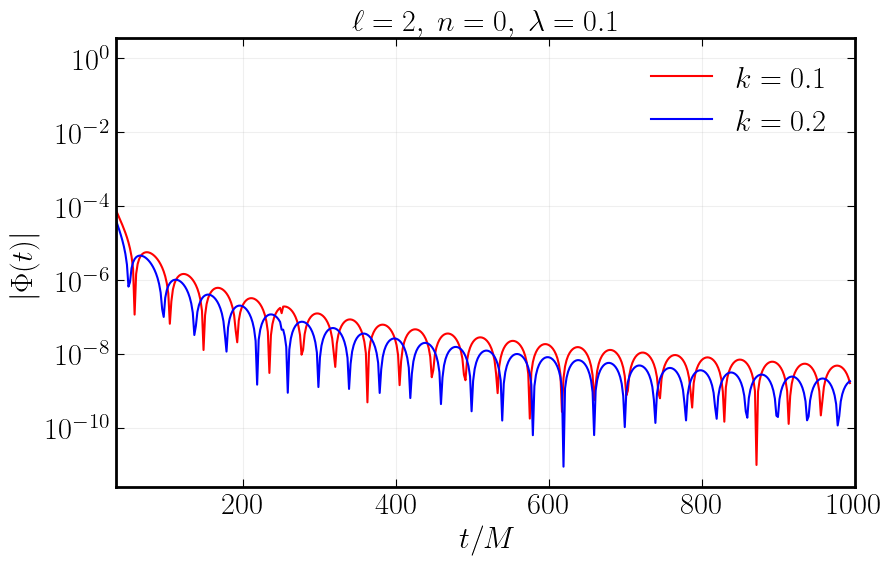

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 18,
    "axes.labelsize": 22,
    "axes.linewidth": 2.0,
    "legend.fontsize": 22,
    "xtick.labelsize": 22,
    "ytick.labelsize": 22,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "legend.frameon": False,
    "savefig.dpi": 600
})

# === Metric and potential ===
def f(r, k, lam):
    return 1/(1 - k) - 2/r + (lam/r) * np.log(r/lam)

def df_dr(r, k, lam):
    return 2/r**2 + (lam/r**2) * (1 - np.log(r/lam))

def V_eff(r, l, mu, k, lam):
    fr = f(r, k, lam)
    dfr = df_dr(r, k, lam)
    return fr * ((l*(l + 1))/r**2 + dfr/r + mu**2)

def horizon_radius(k, lam):
    sol = root_scalar(lambda r: f(r, k, lam), bracket=[1e-3, 50], method='brentq')
    return sol.root

# Tortiose mapping (very approximate)
def r_of_rs(rs):
    return rs + 1.654

# === Time evolution function ===
def evolve(k, lam):
    mu = 0.1
    l = 2
    umin, umax, n = 0, 1000, 500
    vmin, vmax = 1e-5, 200
    h = (umax - umin)/n

    Y = np.zeros((n+1, n+1))
    vc = 4.0
    vl = 2.0

    # Initial Gaussian pulse
    for j in range(n+1):
        v = vmin + j*h
        Y[0, j] = np.exp(-0.00000010 * (v - vc)**2)
        if abs(Y[0, j]) < 1e-64:
            Y[0, j] = 0
        Y[j, j] = 0

    # Evolution
    for i in range(1, n+1):
        for j in range(i+1, n+1):
            u = umin + i*h
            v = vmin + j*h
            rs = (v - u)/2
            rr = r_of_rs(rs)
            VS = V_eff(rr, l, mu, k, lam)
            YS, YE, YW = Y[i-1, j-1], Y[i-1, j], Y[i, j-1]
            Y[i, j] = (YE + YW)*(1 - 0.5*h**2*VS/8) - YS

    # Extract waveform
    rs_obs = 5
    data_t, data_psi = [], []
    for i in range(n+1):
        v = vmin + i*h
        u = v - 2*rs_obs
        iu = int((u - umin)/h)
        iv = int((v - vmin)/h)
        if 0 <= iu < n and 0 <= iv < n:
            t = 0.5*(u + v)
            data_t.append(t)
            data_psi.append(abs(Y[iu, iv]))

    return np.array(data_t), np.array(data_psi)


# === Try multiple k values ===
k_values = [0.1,0.2]
lam = 0.1  # Fixed λ

colors = ["red", "blue"]   # your custom colors

plt.figure(figsize=(9,6))

for k, col in zip(k_values, colors):
    t, psi = evolve(k, lam)    # lam_fixed — choose your value
    plt.plot(t, psi, color=col, label=rf"$k = {k}$")


plt.yscale("log")
#plt.xlabel("t/M", fontsize=17)
#plt.ylabel("|Φ(t)|", fontsize=17)
#plt.title(r"$\ell=2$,$n$=0, $k = 0.1$", fontsize=17)
plt.xlabel(r"$t/M$")
plt.ylabel(r"$|\Phi(t)|$")
plt.title(r"$\ell=2,\; n=0,\; \lambda=0.1$")
plt.legend(fontsize=22)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.tick_params(which="both",
                direction="in",
                top=True,
                right=True)
plt.legend(
    loc="best",
    frameon=False
)
plt.tick_params(axis='both', labelsize=22)
plt.xlim(35,1000)
plt.savefig("wave_t for diff k.pdf", format='pdf',dpi=600,
    bbox_inches="tight",
    pad_inches=0.05)
plt.show()


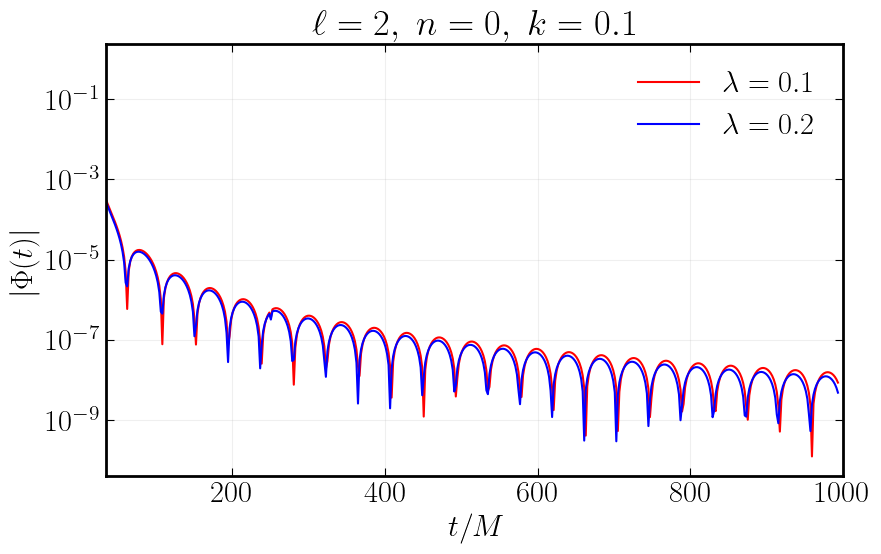

In [36]:
import numpy as np
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "font.size": 22,
    "axes.labelsize": 22,
    "axes.linewidth": 2.0,
    "legend.fontsize": 22,
    "xtick.labelsize": 22,
    "ytick.labelsize": 22,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "legend.frameon": False,
    "savefig.dpi": 600
})

# === Metric and potential ===
def f(r, k, lam):
    return 1/(1 - k) - 2/r + (lam/r) * np.log(r/lam)

def df_dr(r, k, lam):
    return 2/r**2 + (lam/r**2) * (1 - np.log(r/lam))

def V_eff(r, l, mu, k, lam):
    fr = f(r, k, lam)
    dfr = df_dr(r, k, lam)
    return fr * ((l*(l + 1))/r**2 + dfr/r + mu**2)

def horizon_radius(k, lam):
    sol = root_scalar(lambda r: f(r, k, lam), bracket=[1e-3, 50], method='brentq')
    return sol.root

# Tortoise mapping (approximate)
def r_of_rs(rs):
    return rs + 1.654

# === Full evolution function ===
def evolve(k, lam):
    mu = 0.1
    l = 2
    umin, umax, n = 0, 1000, 500
    vmin, vmax = 1e-5, 200
    h = (umax - umin)/n

    Y = np.zeros((n+1, n+1))
    vc = 4.0

    # --- Initial Pulse ---
    for j in range(n+1):
        v = vmin + j*h
        Y[0, j] = np.exp(-10 * (v - vc)**2)
        if abs(Y[0, j]) < 1e-64:
            Y[0, j] = 0
        Y[j, j] = 0

    # --- Evolution ---
    for i in range(1, n+1):
        for j in range(i+1, n+1):
            u = umin + i*h
            v = vmin + j*h
            rs = (v - u)/2
            rr = r_of_rs(rs)
            VS = V_eff(rr, l, mu, k, lam)
            YS, YE, YW = Y[i-1, j-1], Y[i-1, j], Y[i, j-1]
            Y[i, j] = (YE + YW)*(1 - 0.5*h**2*VS/8) - YS

    # --- Extract waveform at rs_obs ---
    rs_obs = 5
    data_t, data_psi = [], []
    for i in range(n+1):
        v = vmin + i*h
        u = v - 2*rs_obs
        iu = int((u - umin)/h)
        iv = int((v - vmin)/h)
        if 0 <= iu < n and 0 <= iv < n:
            t = 0.5*(u + v)
            data_t.append(t)
            data_psi.append(abs(Y[iu, iv]))

    return np.array(data_t), np.array(data_psi)


# === Different lambda values (k fixed) ===
k_fixed = 0.1
lambda_values = [0.1, 0.2]
colors = ["red", "blue"]   # your custom colors

plt.figure(figsize=(9,6))

for lam, col in zip(lambda_values, colors):
    t, psi = evolve(k_fixed, lam)
    plt.plot(t, psi, color=col, label=rf"$\lambda={lam}$")

plt.yscale("log")
#plt.xlabel("t/M", fontsize=17)
#plt.ylabel("|Φ(t)|", fontsize=17)
#plt.title(r"$\ell=2$,$n$=0, $k = 0.1$", fontsize=17)
plt.xlabel(r"$t/M$")
plt.ylabel(r"$|\Phi(t)|$")
plt.title(r"$\ell=2,\; n=0,\; k=0.1$")
plt.legend(fontsize=22)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.tick_params(which="both",
                direction="in",
                top=True,
                right=True)
plt.legend(
    loc="best",
    frameon=False
)
plt.tick_params(axis='both', labelsize=22)
plt.xlim(35,1000)
#plt.ylim(1e-10,1e-2)
plt.savefig("wave_t for diff lambda.pdf", format='pdf',dpi=600,
    bbox_inches="tight",
    pad_inches=0.05)
plt.show()



=== Extracted QNM ===
ω_R = 0.24070499367788753
ω_I = -0.020474448115440726


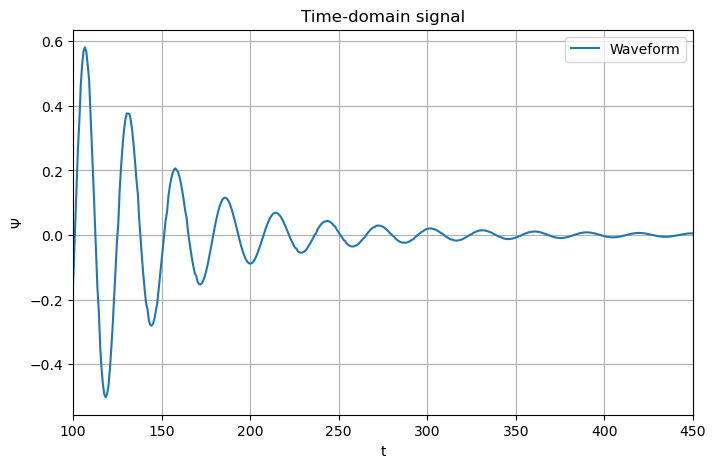

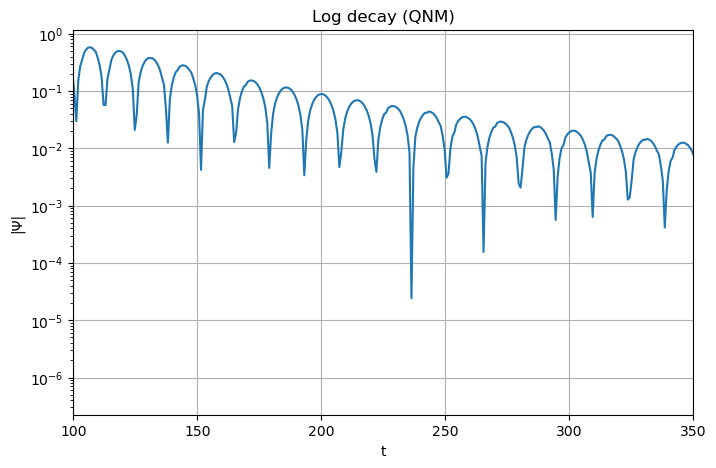

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar, curve_fit

# =========================
# Metric and potential
# =========================
def f(r, k, lam):
    return 1/(1 - k) - 2/r + (lam/r) * np.log(r/lam)

def df_dr(r, k, lam):
    return 2/r**2 + (lam/r**2) * (1 - np.log(r/lam))

def V_eff(r, l, mu, k, lam):
    fr = f(r, k, lam)
    dfr = df_dr(r, k, lam)
    return fr * (l*(l+1)/r**2 + dfr/r + mu**2)

# Horizon
def horizon_radius(k, lam):
    sol = root_scalar(lambda r: f(r, k, lam), bracket=[1e-3, 50])
    return sol.root

# =========================
# Approximate tortoise map
# =========================
def r_of_rs(rs):
    # better than constant shift
    return rs + 2*np.log(rs + 1.0) + 3.0

# =========================
# Time-domain evolution
# =========================
def evolve(k=0.1, lam=0.1, l=2, mu=0.2):

    # grid
    umin, umax, N = 0, 550, 700
    vmin, vmax = 0, 500
    h = (umax - umin)/N

    Y = np.zeros((N+1, N+1))

    # Gaussian initial data
    C = 1.0
    vc = 50.0
    sigma = 5.0

    for j in range(N+1):
        v = vmin + j*h
        Y[0, j] = C * np.exp(-(v - vc)**2 / (2*sigma**2))

    # evolution
    for i in range(1, N+1):
        for j in range(i+1, N+1):
            u = umin + i*h
            v = vmin + j*h

            rs = (v - u)/2
            r = r_of_rs(rs)

            V = V_eff(r, l, mu, k, lam)

            YS = Y[i-1, j-1]
            YE = Y[i-1, j]
            YW = Y[i, j-1]

            Y[i, j] = (YE + YW)*(1 - h**2 * V / 8) - YS

    # =========================
    # waveform extraction
    # =========================
    rs_obs = 30.0
    t_list, psi_list = [], []

    for i in range(N+1):
        v = vmin + i*h
        u = v - 2*rs_obs

        iu = int((u - umin)/h)
        iv = int((v - vmin)/h)

        if 0 <= iu < N and 0 <= iv < N:
            t = 0.5*(u + v)
            psi = Y[iu, iv]

            t_list.append(t)
            psi_list.append(psi)

    return np.array(t_list), np.array(psi_list)

# =========================
# QNM fitting
# =========================
def qnm_model(t, A, wr, wi, phi):
    return A * np.exp(wi*t) * np.cos(wr*t + phi)

def extract_qnm(t, psi):

    # choose late-time region
    mask = (t > 100) & (t < 250)
    t_fit = t[mask]
    psi_fit = psi[mask]

    # initial guess
    p0 = [1.0, 0.4, -0.05, 0.0]

    popt, _ = curve_fit(qnm_model, t_fit, psi_fit, p0=p0)

    A, wr, wi, phi = popt

    return wr, wi

# =========================
# RUN
# =========================
k = 0.1
lam = 0.3

t, psi = evolve(k, lam)

# extract frequency
wr, wi = extract_qnm(t, psi)

print("\n=== Extracted QNM ===")
print("ω_R =", wr)
print("ω_I =", wi)

# =========================
# Plot
# =========================
plt.figure(figsize=(8,5))
plt.plot(t, psi, label="Waveform")
plt.xlabel("t")
plt.ylabel("Ψ")
plt.xlim(100,450)
plt.title("Time-domain signal")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8,5))
plt.semilogy(t, np.abs(psi))
plt.xlabel("t")
plt.ylabel("|Ψ|")
plt.xlim(100,350)
plt.title("Log decay (QNM)")
plt.grid()
plt.show()

### Fit garaph

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =========================
# QNM model
# =========================
def qnm_model(t, A, wr, wi, phi):
    return A * np.exp(wi*t) * np.cos(wr*t + phi)

# =========================
# Fit + Plot function
# =========================
def plot_qnm_fit(t, psi):

    # --- Late-time window ---
    t_min, t_max = 100, 250
    mask = (t > t_min) & (t < t_max)

    t_fit = t[mask]
    psi_fit = psi[mask]

    # --- Fit ---
    p0 = [1.0, 0.4, -0.05, 0.0]
    popt, _ = curve_fit(qnm_model, t_fit, psi_fit, p0=p0)

    A, wr, wi, phi = popt

    print("\n=== Fitted QNM ===")
    print("ω_R =", wr)
    print("ω_I =", wi)

    # --- Smooth fit curve ---
    t_smooth = np.linspace(t_min, t_max, 2000)
    psi_smooth = qnm_model(t_smooth, *popt)

    # =========================
    # FIGURE 1: Waveform + Fit
    # =========================
    plt.figure(figsize=(8,5))

    plt.plot(t, psi, lw=1.2, label="Time-domain signal")
    plt.plot(t_smooth, psi_smooth, 'r--', lw=2,
             label="QNM fit")

    plt.axvspan(t_min, t_max, color='gray', alpha=0.2,
                label="Fitting window")

    plt.xlabel(r"$t/M$", fontsize=14)
    plt.ylabel(r"$\Psi(t)$", fontsize=14)

    plt.title(r"Time-domain waveform and QNM fit", fontsize=14)

    plt.legend(fontsize=12)
    plt.grid(alpha=0.4)
    plt.tight_layout()

    plt.savefig("QNM_fit_waveform.pdf", dpi=300)
    plt.show()

    # =========================
    # FIGURE 2: Log decay
    # =========================
    plt.figure(figsize=(8,5))

    plt.semilogy(t, np.abs(psi), lw=1.2,
                 label="|Ψ(t)|")

    plt.semilogy(t_smooth, np.abs(psi_smooth), 'r--', lw=2,
                 label="Fit envelope")

    plt.axvspan(t_min, t_max, color='gray', alpha=0.2)

    plt.xlabel(r"$t/M$", fontsize=14)
    plt.ylabel(r"$|\Psi(t)|$", fontsize=14)

    plt.title(r"Late-time decay of perturbation", fontsize=14)

    plt.legend(fontsize=12)
    plt.grid(alpha=0.4)
    plt.tight_layout()

    plt.savefig("QNM_decay_log.pdf", dpi=300)
    plt.show()

    return wr, wi

In [14]:
import os

os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]

In [15]:
import shutil
print(shutil.which("pdflatex"))

/Library/TeX/texbin/pdflatex


In [16]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
})

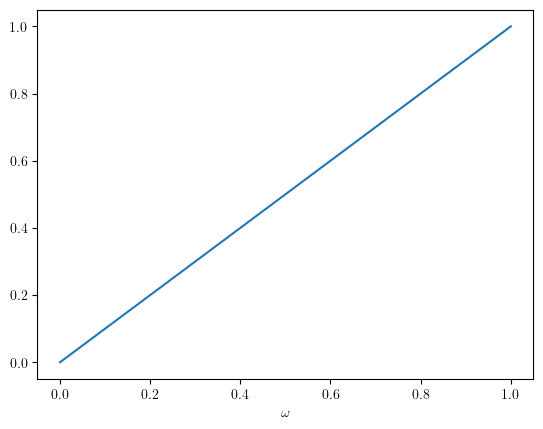

In [21]:
import matplotlib.pyplot as plt

plt.rcParams["text.usetex"] = True

plt.figure()
plt.plot([0,1],[0,1])
plt.xlabel(r'$\omega$')
plt.show()